# Classificação de `Energy_Class` — Renewable Energy Production Dataset

- Arthur Araujo Massarioli	- RM: 573308
- Daniel Alejandro Pupo Martínez -	RM: 573075
- Victor Hugo Lavaqui -	RM: 573838
- Wendel Pedro Rezende -	RM: 573126



In [ ]:
# 1. Importação das bibliotecas
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay, accuracy_score,
    precision_score, recall_score, classification_report
)

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)
RANDOM_STATE = 42


In [ ]:
# 2. Carregamento do dataset
# O notebook procura o CSV na pasta atual e, se necessário, na pasta /mnt/data.
possiveis_caminhos = [
    Path("Renewable_Energy_Data.csv"),
    Path.cwd() / "Renewable_Energy_Data.csv",
    Path("/mnt/data/Renewable_Energy_Data.csv"),
]

DATA_PATH = next((p for p in possiveis_caminhos if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "Não encontrei Renewable_Energy_Data.csv. Coloque o arquivo na mesma pasta do notebook."
    )

df = pd.read_csv(DATA_PATH)
if "Energy_Class" not in df.columns:
    raise ValueError("A coluna-alvo 'Energy_Class' não foi encontrada no dataset.")
if df["Energy_Class"].isna().any():
    raise ValueError("A coluna Energy_Class contém valores ausentes. Trate-os antes de continuar.")

print(f"Arquivo carregado: {DATA_PATH}")
print(f"Dimensões: {df.shape[0]} linhas e {df.shape[1]} colunas")
display(df.head())
display(df.dtypes.rename("tipo de dado").to_frame())
print("\nDistribuição original da variável-alvo:")
display(df["Energy_Class"].value_counts(dropna=False).rename_axis("Energy_Class").to_frame("quantidade"))


Arquivo carregado: Renewable_Energy_Data.csv
Dimensões: 1000 linhas e 11 colunas


,Region,Energy_Source,Temperature_C,Wind_Speed_m_s,Solar_Radiation_kWh_m2,Rainfall_mm,Season,Efficiency_Ratio,Lagged_Production_MWh,Combined_Weather_Index,Energy_Class
0,North,Hydro,13.820937,14.362462,8.834648,3.350827,Winter,125.449109,1419.514155,1.565158,Medium
1,North,Solar,36.972782,19.110474,4.483191,48.767157,Winter,16.325089,4769.329958,0.621331,Low
2,East,Hydro,33.972875,0.364652,5.104325,40.848695,Winter,155.637061,1005.077719,0.156378,High
3,South,Solar,-2.965160,3.915560,6.265925,42.627371,Spring,675.516566,6294.250931,-5.180996,High
4,North,Wind,-3.813486,0.151257,9.263826,46.898262,Spring,626.048277,5550.263638,-3.346412,Medium


,tipo de dado
Region,object
Energy_Source,object
Temperature_C,float64
Wind_Speed_m_s,float64
Solar_Radiation_kWh_m2,float64
Rainfall_mm,float64
Season,object
Efficiency_Ratio,float64
Lagged_Production_MWh,float64
Combined_Weather_Index,float64



Distribuição original da variável-alvo:


,quantidade
Energy_Class,
High,486
Medium,336
Low,178


## 3. Encoding da variável-alvo

Para as classes conhecidas, a codificação é `Low = 0`, `Medium = 1` e `High = 2`. Se o CSV contiver classes diferentes, o notebook usa `LabelEncoder` como alternativa e mostra o mapeamento utilizado.


In [ ]:
# 3. Codificação da variável-alvo
class_order = ["Low", "Medium", "High"]
classes_encontradas = set(df["Energy_Class"].astype(str).unique())

if classes_encontradas.issubset(set(class_order)):
    mapping = {classe: codigo for codigo, classe in enumerate(class_order)}
    y = df["Energy_Class"].astype(str).map(mapping).astype(int)
    class_names = [classe for classe in class_order if classe in classes_encontradas]
else:
    label_encoder = LabelEncoder()
    y = pd.Series(
        label_encoder.fit_transform(df["Energy_Class"].astype(str)),
        index=df.index,
        name="Energy_Class"
    )
    mapping = {classe: int(label_encoder.transform([classe])[0]) for classe in label_encoder.classes_}
    class_names = list(label_encoder.classes_)

print("Mapeamento da variável-alvo:")
display(pd.DataFrame({
    "classe_original": list(mapping.keys()),
    "valor_codificado": list(mapping.values())
}))


Mapeamento da variável-alvo:


,classe_original,valor_codificado
0,Low,0
1,Medium,1
2,High,2


## 4. Matriz de correlação

As variáveis categóricas preditoras são transformadas em indicadores binários (*one-hot encoding*) para permitir o cálculo da correlação. A variável-alvo codificada também é incluída. A correlação de Pearson mede associação linear e, isoladamente, não determina o poder preditivo de uma variável.


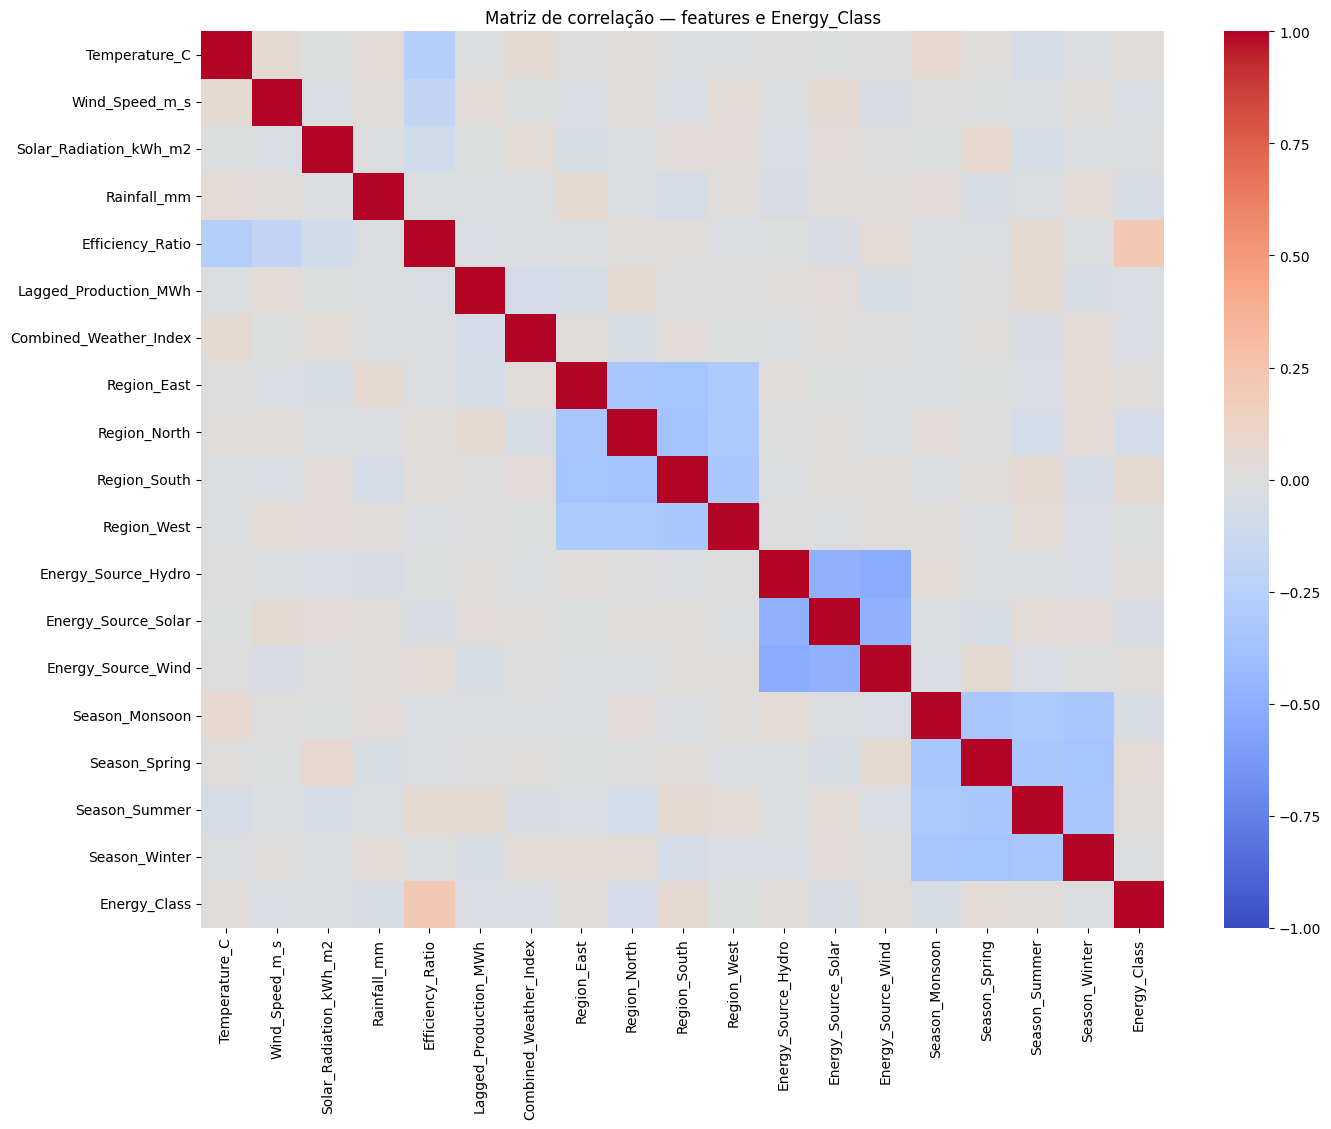

Correlação das variáveis com Energy_Class (ordenada por magnitude absoluta):


,correlacao_com_Energy_Class
Efficiency_Ratio,0.211202
Region_North,-0.065402
Region_South,0.056317
Rainfall_mm,-0.045958
Season_Monsoon,-0.044988
Season_Spring,0.039044
Energy_Source_Solar,-0.035149
Wind_Speed_m_s,-0.027079
Combined_Weather_Index,-0.024515
Lagged_Production_MWh,-0.023716


In [ ]:
# 4. Matriz de correlação entre features codificadas e Energy_Class
X_raw = df.drop(columns=["Energy_Class"]).copy()

categorical_cols_corr = X_raw.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
X_corr = pd.get_dummies(
    X_raw,
    columns=categorical_cols_corr,
    drop_first=False,
    dtype=int
)
dados_correlacao = X_corr.copy()
dados_correlacao["Energy_Class"] = y

matriz_correlacao = dados_correlacao.corr(numeric_only=True)

plt.figure(figsize=(max(12, len(matriz_correlacao.columns) * 0.75),
                    max(9, len(matriz_correlacao.columns) * 0.60)))
sns.heatmap(
    matriz_correlacao,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)
plt.title("Matriz de correlação — features e Energy_Class")
plt.tight_layout()
plt.show()

print("Correlação das variáveis com Energy_Class (ordenada por magnitude absoluta):")
correlacao_alvo = (
    matriz_correlacao["Energy_Class"]
    .drop("Energy_Class")
    .sort_values(key=lambda s: s.abs(), ascending=False)
)
display(correlacao_alvo.rename("correlacao_com_Energy_Class").to_frame())


### Decisão sobre a seleção de features

Neste projeto, são mantidas todas as features disponíveis. Uma correlação linear baixa com `Energy_Class` não prova que uma variável não ajude na classificação, pois o modelo combina informações de várias variáveis e a relação pode não ser linear. A matriz deve ser usada para investigar associações e possíveis redundâncias, enquanto o desempenho final é avaliado nos conjuntos de teste. Variáveis categóricas são codificadas dentro do pipeline, e a padronização é ajustada somente nos dados de treino para evitar vazamento de informação.


## 5. Modelo de classificação linear: Regressão Logística

A Regressão Logística é um classificador linear porque calcula combinações lineares das features transformadas e usa essas combinações para estimar as probabilidades das classes. As fronteiras de decisão entre classes são lineares no espaço das features transformadas.


In [ ]:
# 5. Preparação das features e pipeline de pré-processamento + modelo
X = X_raw.copy()
y_array = y.to_numpy()

numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
categorical_cols = [col for col in X.columns if col not in numeric_cols]

transformadores = []
if numeric_cols:
    transformadores.append(("num", StandardScaler(), numeric_cols))
if categorical_cols:
    transformadores.append((
        "cat",
        OneHotEncoder(handle_unknown="ignore"),
        categorical_cols
    ))

preprocessador = ColumnTransformer(transformers=transformadores, remainder="drop")

modelo = Pipeline(steps=[
    ("preprocessador", preprocessador),
    ("classificador", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))
])

print("Features numéricas:", numeric_cols)
print("Features categóricas:", categorical_cols)
print("Modelo preparado: Regressão Logística")


Features numéricas: ['Temperature_C', 'Wind_Speed_m_s', 'Solar_Radiation_kWh_m2', 'Rainfall_mm', 'Efficiency_Ratio', 'Lagged_Production_MWh', 'Combined_Weather_Index']
Features categóricas: ['Region', 'Energy_Source', 'Season']
Modelo preparado: Regressão Logística


## 6. Treinamento e avaliação nos dois cenários

As condições são mantidas iguais sempre que possível: mesmo modelo, `random_state=42` e divisão estratificada para preservar, aproximadamente, a proporção das classes em treino e teste. A precisão e o recall são calculados como médias ponderadas pelo número de observações de cada classe.



Cenário 1 — 60% treino / 40% teste
Quantidade de registros para treino: 600
Quantidade de registros para teste: 400
Acurácia: 0.7625 (76.25%)
Precisão ponderada: 0.7631 (76.31%)
Recall ponderado: 0.7625 (76.25%)

Matriz de confusão (linhas = classe real; colunas = classe prevista):


,Previsto: Low,Previsto: Medium,Previsto: High
Real: Low,34,33,4
Real: Medium,7,87,40
Real: High,0,11,184


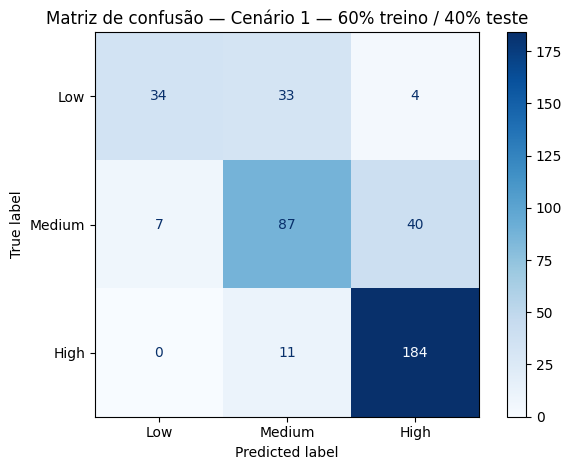

Relatório por classe:


,precision,recall,f1-score,support
Low,0.829268,0.478873,0.607143,71.0000
Medium,0.664122,0.649254,0.656604,134.0000
High,0.807018,0.943590,0.869976,195.0000
accuracy,0.762500,0.762500,0.762500,0.7625
macro avg,0.766803,0.690572,0.711241,400.0000
weighted avg,0.763097,0.762500,0.751844,400.0000



Cenário 2 — 85% treino / 15% teste
Quantidade de registros para treino: 850
Quantidade de registros para teste: 150
Acurácia: 0.7800 (78.00%)
Precisão ponderada: 0.7741 (77.41%)
Recall ponderado: 0.7800 (78.00%)

Matriz de confusão (linhas = classe real; colunas = classe prevista):


,Previsto: Low,Previsto: Medium,Previsto: High
Real: Low,18,9,0
Real: Medium,5,31,14
Real: High,0,5,68


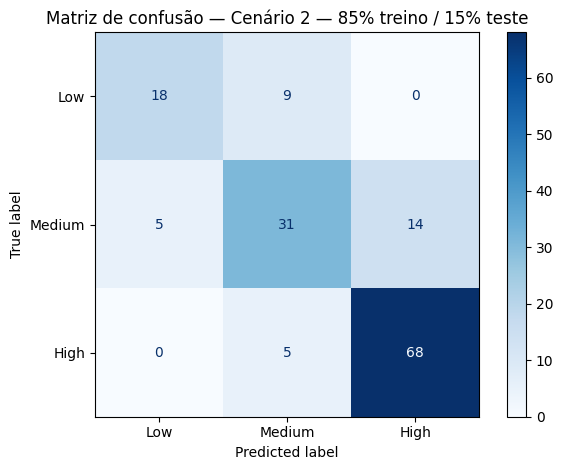

Relatório por classe:


,precision,recall,f1-score,support
Low,0.782609,0.666667,0.720000,27.00
Medium,0.688889,0.620000,0.652632,50.00
High,0.829268,0.931507,0.877419,73.00
accuracy,0.780000,0.780000,0.780000,0.78
macro avg,0.766922,0.739391,0.750017,150.00
weighted avg,0.774076,0.780000,0.774155,150.00


In [ ]:
# 6. Treinar, prever e avaliar os dois cenários
cenarios = [
    {"nome": "Cenário 1 — 60% treino / 40% teste", "test_size": 0.40},
    {"nome": "Cenário 2 — 85% treino / 15% teste", "test_size": 0.15},
]

resultados = []
matrizes_confusao = {}
relatorios = {}
modelos_treinados = {}

labels_codificados = [mapping[c] for c in class_names]

for cenario in cenarios:
    nome = cenario["nome"]
    test_size = cenario["test_size"]

    X_treino, X_teste, y_treino, y_teste = train_test_split(
        X,
        y_array,
        test_size=test_size,
        random_state=RANDOM_STATE,
        stratify=y_array
    )

    # Instância nova por cenário para garantir treinamento independente.
    modelo_cenario = Pipeline(steps=[
        ("preprocessador", ColumnTransformer(
            transformers=[
                ("num", StandardScaler(), numeric_cols),
                ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
            ],
            remainder="drop"
        )),
        ("classificador", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))
    ])

    modelo_cenario.fit(X_treino, y_treino)
    y_previsto = modelo_cenario.predict(X_teste)

    cm = confusion_matrix(y_teste, y_previsto, labels=labels_codificados)
    matrizes_confusao[nome] = cm
    modelos_treinados[nome] = modelo_cenario

    acuracia = accuracy_score(y_teste, y_previsto)
    precisao = precision_score(y_teste, y_previsto, average="weighted", zero_division=0)
    recall = recall_score(y_teste, y_previsto, average="weighted", zero_division=0)

    relatorio = classification_report(
        y_teste,
        y_previsto,
        labels=labels_codificados,
        target_names=class_names,
        zero_division=0,
        output_dict=True
    )
    relatorios[nome] = pd.DataFrame(relatorio).transpose()

    resultados.append({
        "cenario": nome,
        "treino_%": int((1 - test_size) * 100),
        "teste_%": int(test_size * 100),
        "n_treino": len(X_treino),
        "n_teste": len(X_teste),
        "acuracia": acuracia,
        "precisao_ponderada": precisao,
        "recall_ponderado": recall
    })

    print("\n" + "=" * 75)
    print(nome)
    print(f"Quantidade de registros para treino: {len(X_treino)}")
    print(f"Quantidade de registros para teste: {len(X_teste)}")
    print(f"Acurácia: {acuracia:.4f} ({acuracia:.2%})")
    print(f"Precisão ponderada: {precisao:.4f} ({precisao:.2%})")
    print(f"Recall ponderado: {recall:.4f} ({recall:.2%})")

    print("\nMatriz de confusão (linhas = classe real; colunas = classe prevista):")
    display(pd.DataFrame(
        cm,
        index=[f"Real: {c}" for c in class_names],
        columns=[f"Previsto: {c}" for c in class_names]
    ))

    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    disp.plot(cmap="Blues", values_format="d")
    plt.title(f"Matriz de confusão — {nome}")
    plt.tight_layout()
    plt.show()

    print("Relatório por classe:")
    display(relatorios[nome])


## 7. Comparação dos resultados


,cenario,treino_%,teste_%,n_treino,n_teste,acuracia,precisao_ponderada,recall_ponderado
0,Cenário 1 — 60% treino / 40% teste,60,40,600,400,0.7625,0.7631,0.7625
1,Cenário 2 — 85% treino / 15% teste,85,15,850,150,0.7800,0.7741,0.7800


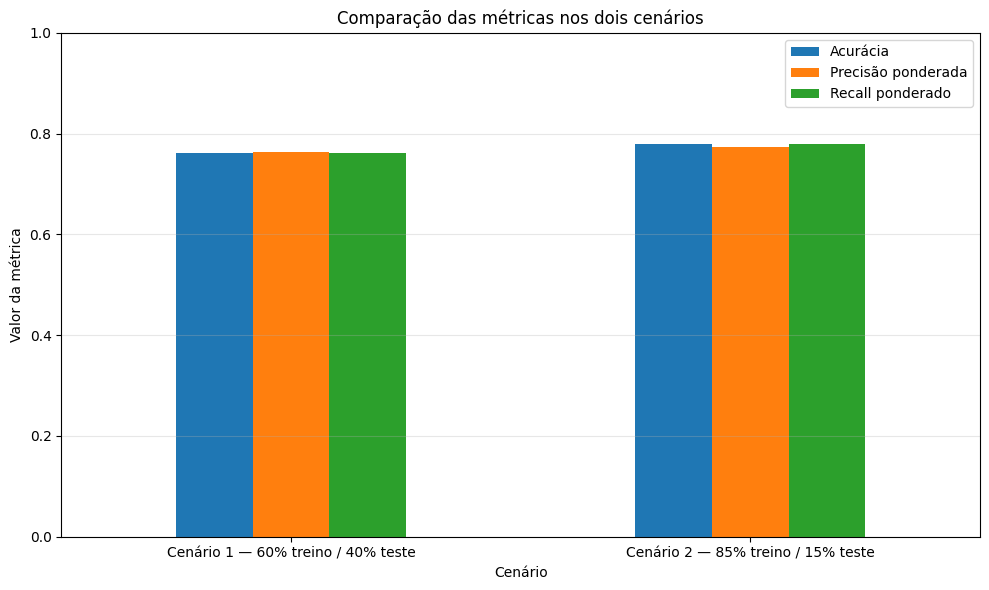

In [ ]:
# 7. Tabela e gráfico de comparação
tabela_resultados = pd.DataFrame(resultados)
display(tabela_resultados.round(4))

metricas = ["acuracia", "precisao_ponderada", "recall_ponderado"]
ax = tabela_resultados.set_index("cenario")[metricas].plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0, 1),
    rot=0
)
ax.set_title("Comparação das métricas nos dois cenários")
ax.set_ylabel("Valor da métrica")
ax.set_xlabel("Cenário")
ax.legend(["Acurácia", "Precisão ponderada", "Recall ponderado"])
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


## 8. Interpretação e conclusão

Use a tabela e as matrizes de confusão geradas acima para concluir se o desempenho é adequado. A acurácia representa a proporção total de previsões corretas; a precisão ponderada resume a proporção de previsões positivas corretas por classe, ponderada pelo suporte; e o recall ponderado resume a proporção de exemplos de cada classe corretamente identificados, também ponderada pelo suporte.

- **40% para teste:** fornece uma avaliação com mais observações no conjunto de teste, mas deixa menos dados disponíveis para treinamento.
- **15% para teste:** disponibiliza mais dados para treinamento, mas a avaliação é feita com menos observações e pode ser mais sensível à composição do teste.
- **Comparação:** uma diferença pequena nas métricas não garante que um cenário seja universalmente melhor. Considere as matrizes de confusão, o desempenho por classe e o tamanho do conjunto de teste.
- **Limitação da correlação:** a correlação de Pearson avalia relações lineares entre pares de variáveis e não mede, sozinha, a utilidade preditiva de cada feature.

A conclusão final deve mencionar os valores efetivamente exibidos pelo notebook e comentar quais classes são mais confundidas.


In [ ]:
# 9. Resumo final para consulta
display(tabela_resultados.round(4))

melhor_acuracia = tabela_resultados.loc[tabela_resultados["acuracia"].idxmax()]
print(
    f"Maior acurácia nesta execução: {melhor_acuracia['cenario']} "
    f"({melhor_acuracia['acuracia']:.2%})."
)
print(
    "Interprete essa diferença junto com as matrizes de confusão: "
    "o conjunto de teste de 40% é maior, enquanto o cenário com 15% de teste "
    "usa mais dados no treinamento."
)


,cenario,treino_%,teste_%,n_treino,n_teste,acuracia,precisao_ponderada,recall_ponderado
0,Cenário 1 — 60% treino / 40% teste,60,40,600,400,0.7625,0.7631,0.7625
1,Cenário 2 — 85% treino / 15% teste,85,15,850,150,0.7800,0.7741,0.7800


Maior acurácia nesta execução: Cenário 2 — 85% treino / 15% teste (78.00%).
Interprete essa diferença junto com as matrizes de confusão: o conjunto de teste de 40% é maior, enquanto o cenário com 15% de teste usa mais dados no treinamento.
